# 09 - Feature Engineering
Machine-learning models understand **numbers only**, and they get confused when one column is in lakhs and another in single digits.
Feature engineering = preparing columns so a model (or an analysis) can use them well.

Today:
1. Univariate analysis - look at one column at a time
2. Label encoding (and decoding back)
3. One-hot encoding
4. Standard scaling
5. Normalization (Min-Max scaling)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler

## Our data - a small used-car table

In [2]:
df = pd.DataFrame({
    "car":          ["Swift", "City", "Creta", "i20", "Baleno", "Verna",
                     "Seltos", "Alto", "Innova", "Polo", "Venue", "Ciaz"],
    "fuel_type":    ["Petrol", "Diesel", "Diesel", "Petrol", "CNG", "Petrol",
                     "Diesel", "CNG", "Diesel", "Petrol", "Petrol", "Diesel"],
    "transmission": ["Manual", "Automatic", "Automatic", "Manual", "Manual", "Automatic",
                     "Automatic", "Manual", "Manual", "Manual", "Automatic", "Manual"],
    "year":         [2018, 2019, 2021, 2017, 2020, 2019, 2022, 2015, 2016, 2018, 2021, 2017],
    "km_driven":    [45000, 38000, 22000, 60000, 30000, 41000, 15000, 80000, 95000, 52000, 25000, 70000],
    "price_lakh":   [5.5, 9.0, 14.5, 4.8, 6.9, 8.5, 16.0, 1.8, 12.0, 5.2, 10.5, 6.0],
})
df

,car,fuel_type,transmission,year,km_driven,price_lakh
0,Swift,Petrol,Manual,2018,45000,5.5
1,City,Diesel,Automatic,2019,38000,9.0
2,Creta,Diesel,Automatic,2021,22000,14.5
3,i20,Petrol,Manual,2017,60000,4.8
4,Baleno,CNG,Manual,2020,30000,6.9
5,Verna,Petrol,Automatic,2019,41000,8.5
6,Seltos,Diesel,Automatic,2022,15000,16.0
7,Alto,CNG,Manual,2015,80000,1.8
8,Innova,Diesel,Manual,2016,95000,12.0
9,Polo,Petrol,Manual,2018,52000,5.2


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   car           12 non-null     str    
 1   fuel_type     12 non-null     str    
 2   transmission  12 non-null     str    
 3   year          12 non-null     int64  
 4   km_driven     12 non-null     int64  
 5   price_lakh    12 non-null     float64
dtypes: float64(1), int64(2), str(3)
memory usage: 704.0 bytes


# 1. Univariate Analysis
*Uni* = one. We study **one column at a time**: its centre, spread and shape.
## 1.1 Numeric columns

In [4]:
df[["year", "km_driven", "price_lakh"]].describe().round(2)

,year,km_driven,price_lakh
count,12.00,12.00,12.00
mean,2018.58,47750.00,8.39
std,2.15,24591.67,4.22
min,2015.00,15000.00,1.80
25%,2017.00,28750.00,5.42
50%,2018.50,43000.00,7.70
75%,2020.25,62500.00,10.88
max,2022.00,95000.00,16.00


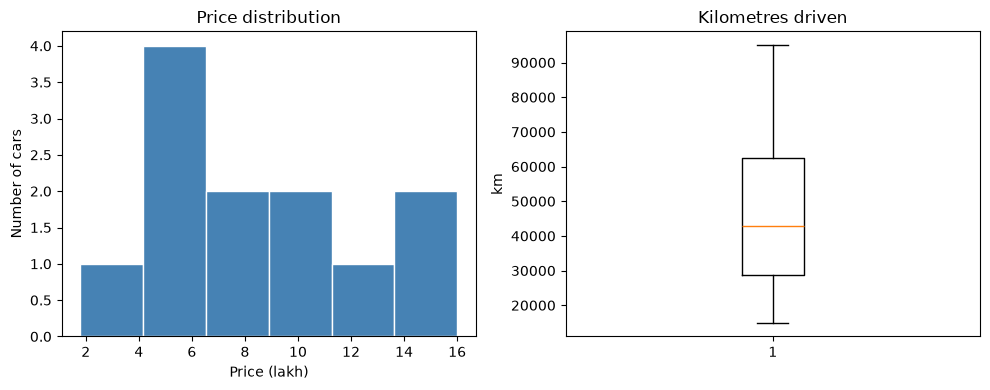

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(df["price_lakh"], bins=6, color="steelblue", edgecolor="white")
axes[0].set_title("Price distribution")
axes[0].set_xlabel("Price (lakh)")
axes[0].set_ylabel("Number of cars")

axes[1].boxplot(df["km_driven"])
axes[1].set_title("Kilometres driven")
axes[1].set_ylabel("km")

plt.tight_layout()
plt.show()

## 1.2 Categorical columns - count each category

In [6]:
print(df["transmission"].value_counts())
print()
print(df["fuel_type"].value_counts())

transmission
Manual       7
Automatic    5
Name: count, dtype: int64

fuel_type
Petrol    5
Diesel    5
CNG       2
Name: count, dtype: int64


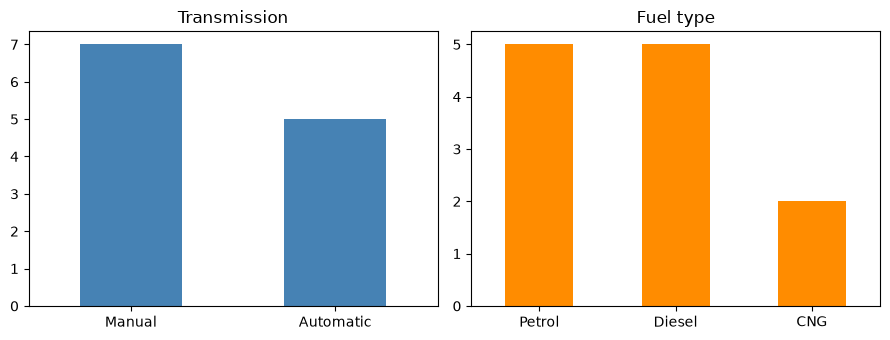

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

df["transmission"].value_counts().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Transmission")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

df["fuel_type"].value_counts().plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Fuel type")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Why does this matter?** Text columns like `transmission` and `fuel_type` cannot go into a model directly.
We must **encode** them as numbers.

# 2. Label Encoding
Label encoding gives every category an integer: alphabetical order → 0, 1, 2 ...
We keep the original column and store the numbers in a **new column**.

In [8]:
le = LabelEncoder()

# fit_transform learns the categories and converts them to numbers
df["transmission_encoded"] = le.fit_transform(df["transmission"])
df[["car", "transmission", "transmission_encoded"]]

,car,transmission,transmission_encoded
0,Swift,Manual,1
1,City,Automatic,0
2,Creta,Automatic,0
3,i20,Manual,1
4,Baleno,Manual,1
5,Verna,Automatic,0
6,Seltos,Automatic,0
7,Alto,Manual,1
8,Innova,Manual,1
9,Polo,Manual,1


What number did each category get?

In [9]:
for number, label in enumerate(le.classes_):
    print(number, "->", label)

0 -> Automatic
1 -> Manual


### Decoding - go back from numbers to text

In [10]:
decoded = le.inverse_transform(df["transmission_encoded"])
print(list(decoded))
print("Same as original? ", (decoded == df["transmission"]).all())

['Manual', 'Automatic', 'Automatic', 'Manual', 'Manual', 'Automatic', 'Automatic', 'Manual', 'Manual', 'Manual', 'Automatic', 'Manual']
Same as original?  True


### Final view: original and encoded columns together

In [11]:
encoded_view = df[["car", "transmission", "transmission_encoded"]]

encoded_view.style \
    .set_caption("Label Encoding of Transmission") \
    .hide(axis="index") \
    .set_table_styles([
        {"selector": "caption", "props": [("font-size", "16px"), ("font-weight", "bold"), ("padding", "8px")]},
        {"selector": "th", "props": [("background-color", "#1f4e79"), ("color", "white"), ("text-align", "center")]},
        {"selector": "td", "props": [("text-align", "center"), ("padding", "6px 14px")]},
    ]) \
    .set_properties(subset=["transmission_encoded"], **{"background-color": "#ffe699", "font-weight": "bold"})

car,transmission,transmission_encoded
Swift,Manual,1
City,Automatic,0
Creta,Automatic,0
i20,Manual,1
Baleno,Manual,1
Verna,Automatic,0
Seltos,Automatic,0
Alto,Manual,1
Innova,Manual,1
Polo,Manual,1


The original `transmission` column is **unchanged** - only a new column was added.

⚠️ Label encoding implies an order (Manual = 1 > Automatic = 0). That is fine for a 2-category column, but for 3+ unordered categories (like fuel type) it misleads a model → use **one-hot encoding**.

# 3. One-Hot Encoding
One new 0/1 column per category. No fake ordering.

In [12]:
fuel_dummies = pd.get_dummies(df["fuel_type"], prefix="fuel", dtype=int)
fuel_dummies

,fuel_CNG,fuel_Diesel,fuel_Petrol
0,0,0,1
1,0,1,0
2,0,1,0
3,0,0,1
4,1,0,0
5,0,0,1
6,0,1,0
7,1,0,0
8,0,1,0
9,0,0,1


In [13]:
df_onehot = pd.concat([df[["car", "fuel_type"]], fuel_dummies], axis=1)
df_onehot

,car,fuel_type,fuel_CNG,fuel_Diesel,fuel_Petrol
0,Swift,Petrol,0,0,1
1,City,Diesel,0,1,0
2,Creta,Diesel,0,1,0
3,i20,Petrol,0,0,1
4,Baleno,CNG,1,0,0
5,Verna,Petrol,0,0,1
6,Seltos,Diesel,0,1,0
7,Alto,CNG,1,0,0
8,Innova,Diesel,0,1,0
9,Polo,Petrol,0,0,1


Tip: `pd.get_dummies(..., drop_first=True)` drops one column because it can be guessed from the others
(if it is not CNG and not Diesel, it must be Petrol). This avoids the *dummy variable trap*.

In [14]:
pd.get_dummies(df["fuel_type"], prefix="fuel", dtype=int, drop_first=True).head(4)

,fuel_Diesel,fuel_Petrol
0,0,1
1,1,0
2,1,0
3,0,1


# 4. Standard Scaling (Z-score)
`km_driven` is in tens of thousands while `price_lakh` is in single digits. Scaling puts them on the same level.

**Formula:** `z = (x - mean) / std`  → result has **mean 0** and **std 1**.

In [15]:
scaler = StandardScaler()
df[["km_scaled", "price_scaled"]] = scaler.fit_transform(df[["km_driven", "price_lakh"]])

df[["car", "km_driven", "km_scaled", "price_lakh", "price_scaled"]].round(2)

,car,km_driven,km_scaled,price_lakh,price_scaled
0,Swift,45000,-0.12,5.5,-0.72
1,City,38000,-0.41,9.0,0.15
2,Creta,22000,-1.09,14.5,1.51
3,i20,60000,0.52,4.8,-0.89
4,Baleno,30000,-0.75,6.9,-0.37
5,Verna,41000,-0.29,8.5,0.03
6,Seltos,15000,-1.39,16.0,1.88
7,Alto,80000,1.37,1.8,-1.63
8,Innova,95000,2.01,12.0,0.89
9,Polo,52000,0.18,5.2,-0.79


In [16]:
print("Mean of km_scaled   :", round(df["km_scaled"].mean(), 4))
print("Std  of km_scaled   :", round(df["km_scaled"].std(ddof=0), 4))

Mean of km_scaled   : 0.0
Std  of km_scaled   : 1.0


Check the formula by hand for the first car:

In [17]:
x = df["km_driven"][0]
manual = (x - df["km_driven"].mean()) / df["km_driven"].std(ddof=0)
print("By hand :", round(manual, 4))
print("Sklearn :", round(df["km_scaled"][0], 4))

By hand : -0.1168
Sklearn : -0.1168


# 5. Normalization (Min-Max Scaling)
Squeezes every value into the range **0 to 1**.

**Formula:** `x_new = (x - min) / (max - min)`

In [18]:
minmax = MinMaxScaler()
df[["km_norm", "price_norm"]] = minmax.fit_transform(df[["km_driven", "price_lakh"]])

df[["car", "km_driven", "km_norm", "price_lakh", "price_norm"]].round(2)

,car,km_driven,km_norm,price_lakh,price_norm
0,Swift,45000,0.38,5.5,0.26
1,City,38000,0.29,9.0,0.51
2,Creta,22000,0.09,14.5,0.89
3,i20,60000,0.56,4.8,0.21
4,Baleno,30000,0.19,6.9,0.36
5,Verna,41000,0.33,8.5,0.47
6,Seltos,15000,0.00,16.0,1.00
7,Alto,80000,0.81,1.8,0.00
8,Innova,95000,1.00,12.0,0.72
9,Polo,52000,0.46,5.2,0.24


In [19]:
print("km_norm   min/max:", df["km_norm"].min(), "/", df["km_norm"].max())
print("price_norm min/max:", df["price_norm"].min(), "/", df["price_norm"].max())

km_norm   min/max: 0.0 / 1.0
price_norm min/max: 0.0 / 1.0


Shape stays the same, only the scale changes:

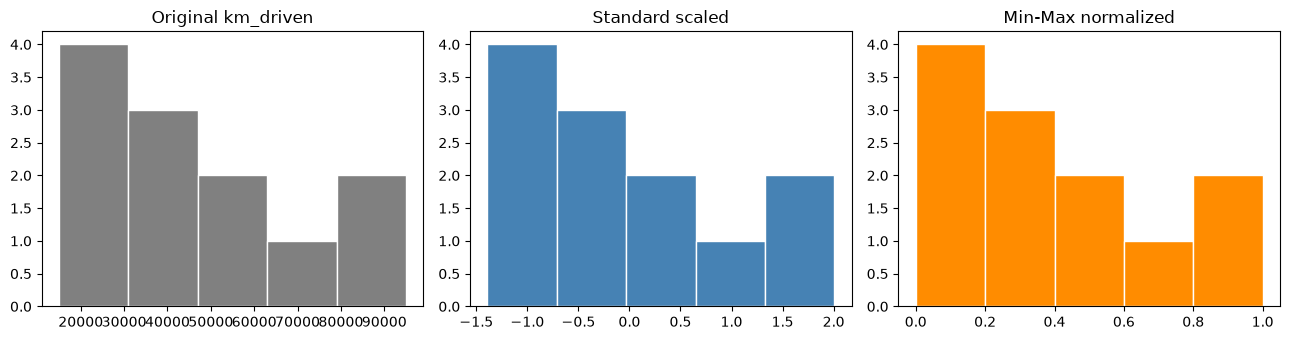

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

axes[0].hist(df["km_driven"], bins=5, color="gray", edgecolor="white")
axes[0].set_title("Original km_driven")

axes[1].hist(df["km_scaled"], bins=5, color="steelblue", edgecolor="white")
axes[1].set_title("Standard scaled")

axes[2].hist(df["km_norm"], bins=5, color="darkorange", edgecolor="white")
axes[2].set_title("Min-Max normalized")

plt.tight_layout()
plt.show()

| | StandardScaler | MinMaxScaler |
|---|---|---|
| Result | mean 0, std 1 | range 0 to 1 |
| Good when | data is roughly bell-shaped; many ML models (regression, SVM, PCA) | you need a fixed range; neural networks, image pixels |
| Weakness | values can be negative | one big outlier squashes everything else |

# 6. Final DataFrame
All engineered columns together.

In [21]:
final_df = pd.concat([df, fuel_dummies], axis=1)
final_df.round(2)

,car,fuel_type,transmission,year,km_driven,price_lakh,transmission_encoded,km_scaled,price_scaled,km_norm,price_norm,fuel_CNG,fuel_Diesel,fuel_Petrol
0,Swift,Petrol,Manual,2018,45000,5.5,1,-0.12,-0.72,0.38,0.26,0,0,1
1,City,Diesel,Automatic,2019,38000,9.0,0,-0.41,0.15,0.29,0.51,0,1,0
2,Creta,Diesel,Automatic,2021,22000,14.5,0,-1.09,1.51,0.09,0.89,0,1,0
3,i20,Petrol,Manual,2017,60000,4.8,1,0.52,-0.89,0.56,0.21,0,0,1
4,Baleno,CNG,Manual,2020,30000,6.9,1,-0.75,-0.37,0.19,0.36,1,0,0
5,Verna,Petrol,Automatic,2019,41000,8.5,0,-0.29,0.03,0.33,0.47,0,0,1
6,Seltos,Diesel,Automatic,2022,15000,16.0,0,-1.39,1.88,0.00,1.00,0,1,0
7,Alto,CNG,Manual,2015,80000,1.8,1,1.37,-1.63,0.81,0.00,1,0,0
8,Innova,Diesel,Manual,2016,95000,12.0,1,2.01,0.89,1.00,0.72,0,1,0
9,Polo,Petrol,Manual,2018,52000,5.2,1,0.18,-0.79,0.46,0.24,0,0,1


In [22]:
final_df.columns.tolist()

['car',
 'fuel_type',
 'transmission',
 'year',
 'km_driven',
 'price_lakh',
 'transmission_encoded',
 'km_scaled',
 'price_scaled',
 'km_norm',
 'price_norm',
 'fuel_CNG',
 'fuel_Diesel',
 'fuel_Petrol']

## Try it yourself
1. Use `LabelEncoder` on `fuel_type`. Compare it with the one-hot result - which is better and why?
2. Apply `StandardScaler` to the `year` column.
3. Decode `transmission_encoded` back to text using `inverse_transform`.

In [23]:
# your code here